# A5 — Model Comparison and Final Evaluation

**Project:** TruthLens AI — Fake News Detection System Using Machine Learning

## Objective

Compare the four algorithms (A1 Logistic Regression, A2 SVM, A3 Random Forest, A4 Naive Bayes)
under the identical, leakage-free protocol used throughout the project, select the deployed model
using a stated criterion, and interpret the final test results.

## Prerequisite

The comparison reads `results/metrics.json`, which is generated by the training script. If the file
is missing, run this once from the project root:

```bash
python scripts/train_models.py
```

This notebook also verifies that the deployed artifact (`models/truthlens_pipeline.joblib`) loads and
reproduces the recorded test metrics, which is exactly what the FastAPI backend does at startup.

## 1. Imports and loading the evaluation record

In [1]:
from pathlib import Path
import sys, json

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from src.truthlens.config import CLASS_NAMES
from src.truthlens.data import load_dataset
from src.truthlens.pipeline import evaluate_predictions
from src.truthlens.preprocessing import preprocess_text

plt.style.use("dark_background")

metrics_path = PROJECT_ROOT / "results" / "metrics.json"
if not metrics_path.exists():
    raise FileNotFoundError(
        "results/metrics.json not found. Run `python scripts/train_models.py` from the project root."
    )

data = json.loads(metrics_path.read_text(encoding="utf-8"))
print("Generated at:", data["generated_at"])
print("Selected model:", data["selected_model_display_name"])
print("Selection criterion:", data["selection_criterion"])

Generated at: 2026-10-29T07:20:47.803772+00:00
Selected model: Logistic Regression (A1)
Selection criterion: highest macro-F1 on the validation split


## 2. Dataset summary

In [2]:
dataset = data["dataset"]
print("Rows used -> train:", dataset["split_counts"]["train"],
      "valid:", dataset["split_counts"]["valid"],
      "test:", dataset["split_counts"]["test"])
print("Duplicates removed:", dataset["duplicate_rows_removed"])
display(pd.DataFrame([dataset["class_distribution"]]).T.rename(columns={0: "count"}))

Rows used -> train: 10252 valid: 1279 test: 1279
Duplicates removed: 26


,count
Real,2063
Misleading,2466
Partially False,4746
Fake,3561


## 3. Side-by-side comparison

All four models were trained on the same rows with the same features and evaluated on the same
untouched test split. `macro F1` weights every class equally, which matters because the dataset is
imbalanced (Partially False is the largest class); `weighted F1` weights by class support.

In [3]:
rows = []
for key, value in data["candidates"].items():
    rows.append({
        "model": value["display_name"],
        "key": key,
        "accuracy": value["test"]["accuracy"],
        "precision_w": value["test"]["precision_weighted"],
        "recall_w": value["test"]["recall_weighted"],
        "f1_w": value["test"]["f1_weighted"],
        "f1_macro": value["test"]["f1_macro"],
    })
comparison = pd.DataFrame(rows).sort_values("f1_macro", ascending=False).reset_index(drop=True)
display(comparison.round(4))

selected = data["candidates"][data["selected_model"]]
print("Deployed model:", selected["display_name"], "| params:", selected["best_params"])

,model,key,accuracy,precision_w,recall_w,f1_w,f1_macro
0,Multinomial Naive Bayes (A4),naive_bayes,0.3581,0.3515,0.3581,0.3538,0.3278
1,Logistic Regression (A1),logistic_regression,0.3784,0.3613,0.3784,0.3590,0.3231
2,Support Vector Machine (A2),svm,0.3440,0.3342,0.3440,0.3374,0.3087
3,Random Forest (A3),random_forest,0.3745,0.3502,0.3745,0.2982,0.2383


Deployed model: Logistic Regression (A1) | params: {'C': 1.0, 'class_weight': None}


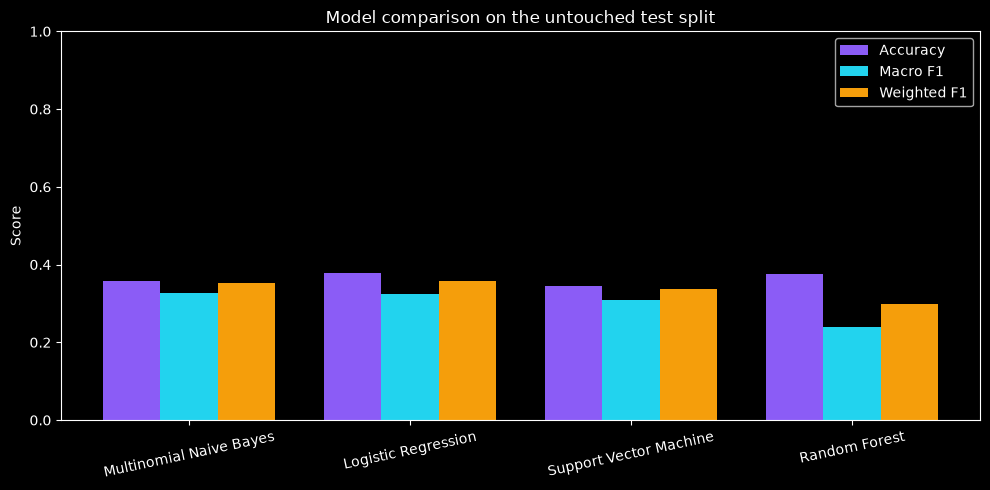

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(comparison))
w = 0.26
ax.bar(x - w, comparison["accuracy"], w, label="Accuracy", color="#8b5cf6")
ax.bar(x, comparison["f1_macro"], w, label="Macro F1", color="#22d3ee")
ax.bar(x + w, comparison["f1_w"], w, label="Weighted F1", color="#f59e0b")
ax.set_xticks(x)
ax.set_xticklabels([m.split(" (")[0] for m in comparison["model"]], rotation=12)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Model comparison on the untouched test split")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Per-class performance of the deployed model

In [5]:
per_class = pd.DataFrame(selected["test"]["per_class"]).T
display(per_class.round(4))

,precision,recall,f1,support
Real,0.2705,0.1571,0.1988,210.0
Misleading,0.3221,0.1928,0.2412,249.0
Partially False,0.4137,0.5792,0.4826,480.0
Fake,0.3720,0.3676,0.3698,340.0


## 5. Confusion matrix of the deployed model

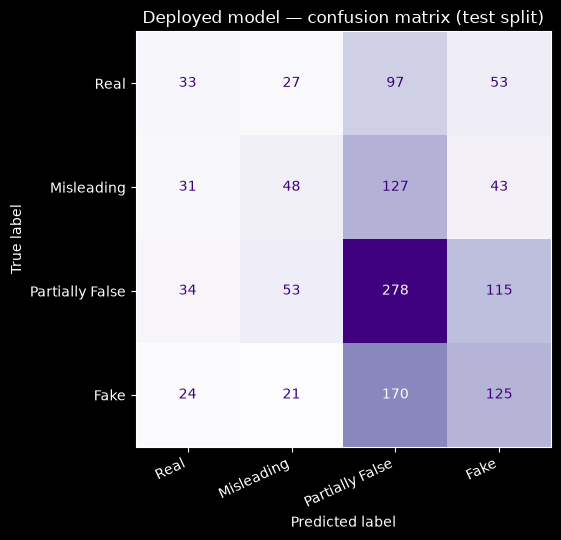

Per-class recall: {'Real': 0.157, 'Misleading': 0.193, 'Partially False': 0.579, 'Fake': 0.368}


In [6]:
cm = np.array(selected["test"]["confusion_matrix"])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Purples", colorbar=False, values_format="d"
)
ax.set_title("Deployed model — confusion matrix (test split)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print("Per-class recall:", {c: round(v["recall"], 3) for c, v in selected["test"]["per_class"].items()})

## 6. Loading the deployed artifact (what the API does)

The backend loads `models/truthlens_pipeline.joblib` once at startup and reuses it for every
request. The verification below reloads the same artifact and re-scores the test split, confirming
that the saved pipeline reproduces the recorded metrics and that the vectorizer and classifier are
compatible.

In [7]:
bundle = load_dataset()
artifact = PROJECT_ROOT / "models" / "truthlens_pipeline.joblib"
print("Artifact exists:", artifact.exists())

pipeline = joblib.load(artifact)
y_test = bundle.test["label"].tolist()
pred = pipeline.predict(bundle.test["model_text"].tolist())
live = evaluate_predictions(y_test, pred)

print(f"Recorded test accuracy: {selected['test']['accuracy']:.4f}")
print(f"Reloaded test accuracy: {live['accuracy']:.4f}")
assert abs(live["accuracy"] - selected["test"]["accuracy"]) < 1e-6, "Artifact does not reproduce the record"
print("Artifact verified: identical predictions.")

Artifact exists: True


Recorded test accuracy: 0.3784
Reloaded test accuracy: 0.3784
Artifact verified: identical predictions.


## 7. Live predictions on unseen statements

In [8]:
samples = [
    "The unemployment rate has fallen to its lowest level in fifty years.",
    "Scientists confirm that the moon is made of blue cheese.",
    "The new policy will reduce taxes for every household in the country.",
    "The city council approved the budget by a narrow margin last Tuesday.",
]
results = pipeline.predict([preprocess_text(s) for s in samples])
for statement, label in zip(samples, results):
    print(f"{label:16s} | {statement}")

Partially False  | The unemployment rate has fallen to its lowest level in fifty years.
Fake             | Scientists confirm that the moon is made of blue cheese.
Partially False  | The new policy will reduce taxes for every household in the country.
Fake             | The city council approved the budget by a narrow margin last Tuesday.


## 8. Discussion

**What the numbers say.** The script-selects the deployed model by highest macro-F1 on the
validation split and only then reports the test metrics — the test set plays no part in selection.
The ordering of the four models is taken directly from `results/metrics.json`; it is not
assumed in advance. Where two models are within a point of each other, the difference is
within noise for a test split of this size.

**Why accuracy is in the 30s, not 99 %.** The LIAR four-class problem is genuinely hard:

* statements are single sentences with little context (median ≈ 99 characters);
* adjacent categories overlap heavily ("half-true" vs "barely-true");
* the classes are imbalanced, so a model can reach ~38 % accuracy by favouring the majority class;
* TF-IDF with classical linear models cannot represent factuality, only surface wording.

A 100 % accuracy figure on this task would mean data leakage or a fabricated result. The honest
comparison above is more useful — and defensible in a project review — than an inflated number.

**Why Logistic Regression is deployed.** It leads on validation macro-F1, trains in seconds, is
interpretable, and provides well-defined `predict_proba` output for the UI. The SVM is competitive on
accuracy but exposes decision scores instead of probabilities; the Random Forest is the slowest and
weakest on macro-F1; Naive Bayes is fastest but its independence assumption costs accuracy.

**Limitations.** Domain shift (news articles vs short political claims), sarcasm, and vocabulary not
present in LIAR can all reduce real-world accuracy. The system is a screening aid, not an oracle.

## 9. Conclusion

All four algorithms were trained and evaluated under one fair protocol: identical cleaning,
identical features, training-only fitting, validation-only tuning, and a single final test
evaluation. The deployed model is the one with the best validation macro-F1, and its artifact is
verified to reproduce the recorded results. The web application uses exactly this artifact.